# AED guiado pelo DAMICORE: armadilhas enganosas concatenadas

**Problema.** Uma cadeia de bits é a concatenação de *m* armadilhas de *k = 5*
bits. Cada armadilha com *u* uns vale *k* se *u = k* e *k − 1 − u* caso
contrário: cada bit sozinho "puxa" para zero, mas o ótimo é tudo um. Os bits de
cada armadilha são **espalhados ao acaso** pela cadeia, então posição vizinha não
diz nada sobre quem anda junto.

**Por que este problema.** É o problema-padrão para AEDs que aprendem
*linkage*: um algoritmo que trata cada bit isoladamente é enganado e converge
para zeros; só quem descobre os grupos verdadeiros e os sorteia inteiros chega
ao ótimo. E, diferente de um conjunto de dados real, aqui **o gabarito da
estrutura é conhecido**: dá para medir diretamente se o DAMICORE achou as
armadilhas.

**Hipótese.** O DAMICORE (NCD → Neighbor Joining → FastGreedy), aplicado às
soluções promissoras de cada geração, recupera as armadilhas (ARI próximo de 1),
e o AED construído com esses grupos resolve problemas de 20 a 80 variáveis com
um número de avaliações que cresce de forma polinomial e moderada com o tamanho.


In [1]:
from pathlib import Path
import json
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import toytree
from IPython.display import display

PROJECT_ROOT = Path.cwd().resolve()
while (
    PROJECT_ROOT != PROJECT_ROOT.parent
    and not (PROJECT_ROOT / "pyproject.toml").exists()
):
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / "pyproject.toml").exists():
    raise RuntimeError("Open this notebook from the repository environment.")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from hypotheses.deceptive_trap_linkage.scripts.config import ARTIFACT_ROOT, DEFAULT_CONFIG
from hypotheses.deceptive_trap_linkage.scripts.trap import make_instance

instance = make_instance(4, DEFAULT_CONFIG.trap_size, seed=1)
print("Armadilhas de um exemplo com 4 blocos (bits espalhados):")
for block, members in enumerate(instance.blocks, start=1):
    print(f"  armadilha {block}: bits {members}")
u = np.arange(DEFAULT_CONFIG.trap_size + 1)
k = DEFAULT_CONFIG.trap_size
display(pd.DataFrame({"uns na armadilha": u, "valor": np.where(u == k, k, k - 1 - u)}).set_index("uns na armadilha").T)


Armadilhas de um exemplo com 4 blocos (bits espalhados):
  armadilha 1: bits (6, 11, 15, 16, 19)
  armadilha 2: bits (0, 4, 9, 10, 13)
  armadilha 3: bits (1, 5, 12, 17, 18)
  armadilha 4: bits (2, 3, 7, 8, 14)


uns na armadilha,0,1,2,3,4,5
valor,4,3,2,1,0,5


## 1. O AED

A cada geração:

1. **Seleção:** os 30% melhores da população são as soluções promissoras.
2. **Um arquivo por variável.** Em vez de escrever o bit de cada solução, o
   arquivo lista **os números das soluções com 0, depois os com 1**. Dois bits
   da mesma armadilha dividem as promissoras do mesmo jeito e escrevem trechos
   parecidos, que o NCD (compressão) enxerga.
3. **DAMICORE agrupa as variáveis:** matriz NCD → árvore Neighbor Joining →
   comunidades FastGreedy. Variáveis constantes ficam sozinhas; arquivos
   idênticos vão juntos (são cópias perfeitas um do outro).
4. **Tabela por grupo:** os padrões de cada grupo vistos nas promissoras, com
   suas frequências.
5. **Amostragem:** cada filho sorteia cada grupo inteiro da sua tabela. Pais e
   filhos competem e os melhores ficam (substituição *plus*).

Não há mistura uniforme nem blocos fixos: a única fonte de estrutura é o DAMICORE.

**Grade:** m ∈ {4, 6, 8, 10, 12, 16} armadilhas (20 a 80 bits) ×
N ∈ {1.000 … 16.000} indivíduos × 10 sementes. Um tamanho N "resolve" um m quando
≥ 90% das sementes acham o ótimo.

A célula abaixo carrega a execução mais recente em `artifacts/`; se não houver
nenhuma, roda o experimento (alguns minutos).


In [2]:
runs_dirs = sorted(p for p in ARTIFACT_ROOT.glob("*") if (p / "audit.json").exists())
if runs_dirs:
    output_dir = runs_dirs[-1]
else:
    from hypotheses.deceptive_trap_linkage.scripts.experiment import execute_experiment
    output_dir = execute_experiment().output_dir

audit = json.loads((output_dir / "audit.json").read_text(encoding="utf-8"))
runs = pd.read_csv(output_dir / "runs.csv")
generations = pd.read_csv(output_dir / "generations.csv")
summary = pd.read_csv(output_dir / "summary.csv")
needed = pd.read_csv(output_dir / "population_needed.csv")
print(f"Artefatos: {output_dir}")
print(f"Execuções: {audit['runs']}, com ótimo: {audit['successful_runs']}")
print(f"Chamadas ao DAMICORE: {audit['damicore_runs']}")


Artefatos: /Users/erickpatrickbarcelos/codes/data-mining/hypotheses/deceptive_trap_linkage/artifacts/20261020T212703Z
Execuções: 360, com ótimo: 244
Chamadas ao DAMICORE: 2751


## 2. Uma geração por dentro

Exemplo com 10 armadilhas (50 bits), menor N que resolve, semente 1: o começo da matriz NCD, a árvore
das variáveis colorida pela armadilha verdadeira, e os grupos que o DAMICORE
devolveu. Na 1ª geração as promissoras ainda são quase aleatórias; algumas
gerações depois a árvore separa as armadilhas.


blocks-10_population-8000
Geração 1: ARI = 0.00, armadilhas exatas = 0


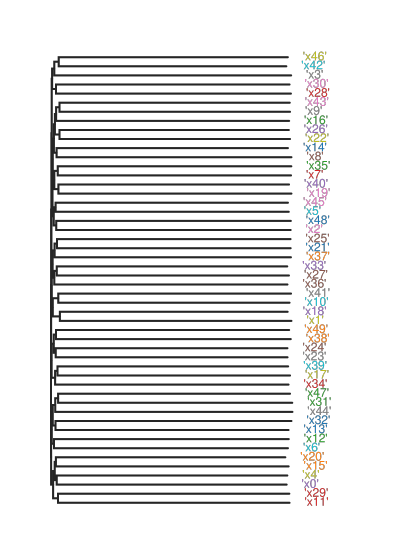

Grupos: [[0, 4, 11, 15, 20, 29], [1, 10, 18, 28, 30, 41], [2, 5, 7, 19, 35, 40, 45, 48], [3, 42, 46], [6, 12, 13, 32], [8, 9, 14, 16, 22, 26, 43], [17, 34, 39], [21, 25, 37], [23, 24, 38, 49], [27, 33, 36], [31, 44, 47]]
Geração 4: ARI = 0.95, armadilhas exatas = 8


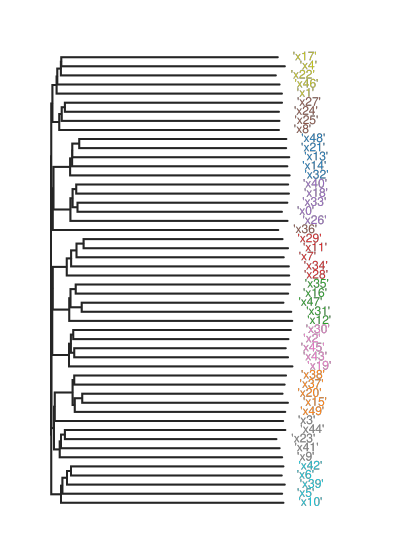

Grupos: [[0, 18, 26, 33, 36, 40], [1, 4, 17, 22, 46], [2, 19, 30, 43, 45], [3, 9, 23, 41, 44], [5, 6, 10, 39, 42], [7, 11, 28, 29, 34], [8, 24, 25, 27], [12, 16, 31, 35, 47], [13, 14, 21, 32, 48], [15, 20, 37, 38, 49]]


In [3]:
example = make_instance(10, DEFAULT_CONFIG.trap_size, seed=DEFAULT_CONFIG.example_seed)
truth = {f"x{v}": b for b, members in enumerate(example.blocks) for v in members}
population = int(needed.loc[needed["block_count"] == 10, "population_size"].iloc[0])
example_dir = output_dir / "examples" / f"blocks-10_population-{population}"
print(example_dir.name)
palette = plt.get_cmap("tab10")
for generation in (1, 4):
    generation_dir = example_dir / f"generation-{generation:02d}"
    if not (generation_dir / "tree.nwk").exists():
        continue
    groups = json.loads((generation_dir / "groups.json").read_text(encoding="utf-8"))
    row = generations.query("block_count == 10 and seed == @DEFAULT_CONFIG.example_seed and generation == @generation")
    row = row.loc[row["population_size"] == population]
    print(f"Geração {generation}: ARI = {row['ari'].iloc[0]:.2f}, "
          f"armadilhas exatas = {row['exact_blocks'].iloc[0]}")
    tree = toytree.tree((generation_dir / "tree.nwk").read_text(encoding="utf-8"))
    colors = [
        "#%02x%02x%02x" % tuple(int(255 * c) for c in palette(truth.get(name.strip("'"), 0))[:3])
        for name in tree.get_tip_labels()
    ]
    canvas, _, _ = tree.draw(width=420, height=560, tip_labels_colors=colors)
    display(canvas)
    print("Grupos:", groups["groups"])


## 3. O DAMICORE achou as armadilhas?

**ARI** (índice de Rand ajustado) compara os grupos do DAMICORE com as armadilhas
verdadeiras: 1 = idênticos, ≈ 0 = acaso. Abaixo, a média por geração para o
menor N que resolve cada tamanho.


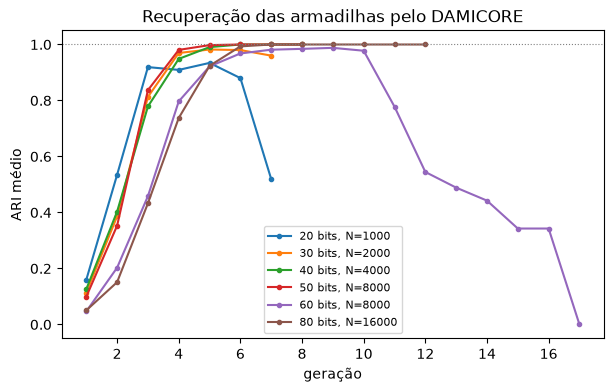

,block_count,population_size,variables,seeds,success_rate,mean_solved_share,mean_generations,mean_evaluations_when_solved,ari_generation_1,ari_best,ari_last,exact_block_share_best
0,4,1000,20,10,1.0,1.000,4.5,5500.000,0.160,0.947,0.902,0.825
1,4,2000,20,10,1.0,1.000,3.2,8400.000,0.236,0.937,0.920,0.800
2,4,4000,20,10,1.0,1.000,2.6,14400.000,0.603,0.940,0.940,0.825
3,4,8000,20,10,1.0,1.000,2.0,24000.000,0.814,0.980,0.980,0.925
4,4,16000,20,10,1.0,1.000,1.4,38400.000,0.937,0.978,0.978,0.944
5,4,32000,20,10,1.0,1.000,1.2,70400.000,0.955,0.965,0.965,0.900
6,6,1000,30,10,0.3,0.800,10.1,8666.667,0.049,0.873,0.260,0.750
7,6,2000,30,10,1.0,1.000,5.4,12800.000,0.114,0.992,0.986,0.967
8,6,4000,30,10,1.0,1.000,4.4,21600.000,0.223,1.000,1.000,1.000
9,6,8000,30,10,1.0,1.000,3.5,36000.000,0.356,1.000,1.000,1.000


In [4]:
fig, ax = plt.subplots(figsize=(7, 4))
for _, row in needed.dropna(subset=["population_size"]).iterrows():
    curve = generations.loc[
        (generations["block_count"] == row["block_count"])
        & (generations["population_size"] == row["population_size"])
    ].groupby("generation")["ari"].mean()
    ax.plot(curve.index, curve.values, marker="o", ms=3,
            label=f"{int(row['variables'])} bits, N={int(row['population_size'])}")
ax.axhline(1, color="grey", lw=0.8, ls=":")
ax.set(xlabel="geração", ylabel="ARI médio", ylim=(-0.05, 1.05),
       title="Recuperação das armadilhas pelo DAMICORE")
ax.legend(fontsize=8)
plt.show()
display(summary.round(3))


## 4. Quanto custa resolver

Menor população testada que resolve cada tamanho, e as avaliações gastas. A
inclinação da reta log-log é o expoente de escala: avaliações ∝ variáveis^b.


,block_count,variables,population_size,success_rate,mean_generations,mean_evaluations_when_solved,ari_best,exact_block_share_best
0,4.0,20.0,1000.0,1.0,4.5,5500.000,0.947,0.825
1,6.0,30.0,2000.0,1.0,5.4,12800.000,0.992,0.967
2,8.0,40.0,4000.0,1.0,7.1,32400.000,1.000,1.000
3,10.0,50.0,8000.0,1.0,7.3,66400.000,1.000,1.000
4,12.0,60.0,8000.0,0.9,10.3,84444.444,0.989,0.983
5,16.0,80.0,16000.0,1.0,11.1,193600.000,1.000,1.000


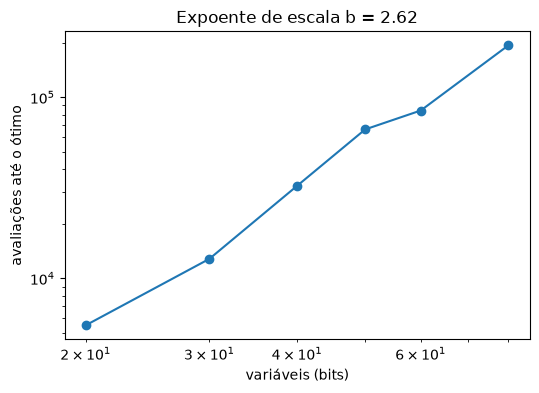

In [5]:
display(needed.round(3))
solved = needed.dropna(subset=["mean_evaluations_when_solved"])
fig, ax = plt.subplots(figsize=(6, 4))
ax.loglog(solved["variables"], solved["mean_evaluations_when_solved"], "o-")
ax.set(xlabel="variáveis (bits)", ylabel="avaliações até o ótimo",
       title=f"Expoente de escala b = {audit['evaluations_scaling_exponent']:.2f}")
plt.show()


## 5. Limites

- Não há comparação com outros métodos nesta hipótese: a evidência é a
  recuperação da estrutura conhecida (ARI), não uma corrida contra baselines.
- A grade de populações é grossa (dobra a cada passo), então o "N necessário"
  e o expoente de escala são aproximados.
- Só armadilhas de 5 bits, sem sobreposição entre elas; problemas com
  dependências sobrepostas ou hierárquicas não foram testados.
- O NCD usa zlib; cada chamada ao DAMICORE custa uma fração de segundo, o que
  cresce com o número de variáveis ao quadrado.
